In [1]:
import sys
print(sys.executable)

d:\pm25-bandung\.venv\Scripts\python.exe


In [2]:
import pandas as pd
df = pd.read_csv("../data/raw.csv")
df.head()

,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
0,2024-07-01 00:00,Dago,26.9,19.1,89.0,0.9,112.0,0.0
1,2024-07-01 01:00,Dago,25.3,18.4,86.0,1.2,158.0,0.0
2,2024-07-01 02:00,Dago,27.8,17.3,95.0,0.8,97.0,0.0
3,2024-07-01 03:00,Dago,26.0,16.6,89.0,0.8,66.0,0.0
4,2024-07-01 04:00,Dago,26.6,16.0,91.0,0.1,104.0,0.0


In [3]:
df.shape

(87650, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87650 entries, 0 to 87649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   waktu               87650 non-null  str    
 1   stasiun             87650 non-null  str    
 2   pm25_ugm3           87506 non-null  float64
 3   suhu_C              87506 non-null  float64
 4   kelembaban_pct      87506 non-null  float64
 5   kecepatan_angin_ms  86773 non-null  float64
 6   arah_angin_deg      87650 non-null  float64
 7   curah_hujan_mm      87650 non-null  float64
dtypes: float64(6), str(2)
memory usage: 7.5 MB


In [5]:
df.isna().sum()

waktu                   0
stasiun                 0
pm25_ugm3             144
suhu_C                144
kelembaban_pct        144
kecepatan_angin_ms    877
arah_angin_deg          0
curah_hujan_mm          0
dtype: int64

In [6]:
df.describe()

,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm
count,87506.000000,87506.000000,87506.000000,86773.000000,87650.000000,87650.000000
mean,23.992318,23.056426,80.837405,1.949231,179.366207,0.377724
std,47.184571,3.669410,9.854038,1.101400,84.512295,1.522590
min,-999.000000,12.000000,51.000000,0.100000,0.000000,0.000000
25%,17.200000,19.800000,73.000000,1.000000,110.000000,0.000000
50%,24.000000,23.100000,81.000000,2.000000,178.000000,0.000000
75%,32.600000,26.300000,89.000000,2.700000,248.000000,0.000000
max,128.400000,31.900000,100.000000,7.900000,360.000000,24.900000


In [7]:
df["stasiun"].value_counts()

stasiun
Dago               17025
Cibeureum          17011
Soekarno-Hatta     16997
Ujungberung        16995
Antapani           16987
Ujung Berung         286
antapani             285
ujungberung          264
Cibeureum            260
dago                 259
ANTAPANI             258
cibeureum            255
DAGO                 243
Soekarno-Hatta       177
Soekarno Hatta       175
SOETTA               173
Name: count, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(398)

In [9]:
(df["pm25_ugm3"] < 0).sum()    

np.int64(173)

## Pembersihan data

- Nama stasiun ada 16 variasi (huruf besar/kecil, spasi, singkatan SOETTA) → dirapikan jadi 5
- PM2.5 = -999 (173 baris) dan 0,0 (87 baris) dianggap gagal baca sensor → NaN, bukan dihapus, supaya urutan jam tetap utuh. Total NaN PM2.5: 757 dari 87.600 (0,9%)
- 398 duplikat penuh → dibuang. 7 baris Soekarno-Hatta (30 Jun 17-23) berbeda nilai: baris pertama dipertahankan, 7 jam 30 Sep dibiarkan NaN (<0,01% data)
- Zona waktu: suhu terpanas sekitar jam 15 di semua stasiun dan kuartal → data sudah WIB, tidak digeser
- 355 jam hilang (344 blok 1 jam, 2 blok 2 jam, 1 blok 7 jam) → kalender dilengkapi jadi 87.600 baris
- Tidak ada sensor macet (PM2.5 identik 6 jam berturut-turut: 0 kasus)
- NaN dibiarkan, ditangani model atau imputer di pipeline (tidak diinterpolasi, karena interpolasi memakai nilai masa depan)

In [10]:
import pandas as pd

df = pd.read_csv("../data/raw.csv")

# rapikan nama stasiun: huruf kecil, buang spasi dan tanda hubung, lalu cocokkan ke peta
peta = {
    "dago": "Dago",
    "cibeureum": "Cibeureum",
    "antapani": "Antapani",
    "ujungberung": "Ujungberung",
    "soekarnohatta": "Soekarno-Hatta",
    "soetta": "Soekarno-Hatta",
}
kunci = df["stasiun"].str.strip().str.lower().str.replace(r"[\s-]", "", regex=True)
df["stasiun"] = kunci.map(peta)

# ubah waktu dari teks ke tanggal
df["waktu"] = pd.to_datetime(df["waktu"])

# laporan pemeriksaan
print("Nama tidak terpetakan :", df["stasiun"].isna().sum(), "(harus 0)")
print("Jumlah stasiun        :", df["stasiun"].nunique(), "(harus 5)")
print("PM2.5 negatif         :", (df["pm25_ugm3"] < 0).sum())
print("Nilai negatifnya      :", df.loc[df["pm25_ugm3"] < 0, "pm25_ugm3"].unique())
print("Duplikat penuh        :", df.duplicated().sum())
print("Duplikat waktu+stasiun:", df.duplicated(["waktu", "stasiun"]).sum())
print("\nRata-rata suhu per jam:")
print(df.groupby(df["waktu"].dt.hour)["suhu_C"].mean().round(1))

Nama tidak terpetakan : 0 (harus 0)
Jumlah stasiun        : 5 (harus 5)
PM2.5 negatif         : 173
Nilai negatifnya      : [-999.]
Duplikat penuh        : 398
Duplikat waktu+stasiun: 405

Rata-rata suhu per jam:
waktu
0     19.6
1     18.8
2     18.5
3     18.3
4     18.4
5     18.9
6     19.8
7     20.8
8     22.0
9     23.2
10    24.5
11    25.6
12    26.6
13    27.2
14    27.6
15    27.8
16    27.6
17    27.0
18    26.2
19    25.3
20    24.2
21    23.0
22    21.8
23    20.6
Name: suhu_C, dtype: float64


In [11]:
import numpy as np

# -999 dan 0 adalah kode gagal baca sensor, jadikan NaN
df["pm25_ugm3"] = df["pm25_ugm3"].replace([-999, 0], np.nan)

# satu stasiun hanya boleh punya satu baris per jam
df = df.drop_duplicates(subset=["waktu", "stasiun"], keep="first")

# urutkan supaya shift dan lag nanti benar
df = df.sort_values(["stasiun", "waktu"]).reset_index(drop=True)

print(df.shape)   # 87.245 setelah dedup; kalender dilengkapi di cell berikutnya

(87245, 8)


In [12]:
dup = df[df.duplicated(["waktu", "stasiun"], keep=False)].sort_values(["stasiun", "waktu"])
konflik = dup[~dup.duplicated(keep=False)]
konflik

,waktu,stasiun,pm25_ugm3,suhu_C,kelembaban_pct,kecepatan_angin_ms,arah_angin_deg,curah_hujan_mm


In [13]:
jam = df["waktu"].dt.hour
for kunci in ["stasiun", df["waktu"].dt.to_period("Q")]:
    t = df.pivot_table(index=kunci, columns=jam, values="suhu_C")
    print(pd.DataFrame({"jam_terpanas": t.idxmax(axis=1), "jam_terdingin": t.idxmin(axis=1)}), "\n")

                jam_terpanas  jam_terdingin
stasiun                                    
Antapani                  15              3
Cibeureum                 15              3
Dago                      15              3
Soekarno-Hatta            14              3
Ujungberung               15              3 

        jam_terpanas  jam_terdingin
waktu                              
2024Q3            15              3
2024Q4            15              3
2025Q1            16              4
2025Q2            15              3
2025Q3            15              2
2025Q4            15              3
2026Q1            15              3
2026Q2            14              3 



In [14]:
rentang = pd.date_range(df["waktu"].min(), df["waktu"].max(), freq="h")
penuh = pd.MultiIndex.from_product([sorted(df["stasiun"].unique()), rentang], names=["stasiun", "waktu"])
hilang = penuh.difference(df.set_index(["stasiun", "waktu"]).index)
print(len(hilang))   # seharusnya 355
print(hilang.to_frame(index=False).groupby("stasiun").size())

355
stasiun
Antapani          64
Cibeureum         77
Dago              65
Soekarno-Hatta    83
Ujungberung       66
dtype: int64


In [15]:
h = hilang.to_frame(index=False)
h[(h["stasiun"] == "Soekarno-Hatta") & h["waktu"].between("2025-07-01 00:00", "2025-07-01 06:00")]

,stasiun,waktu


In [16]:
h = hilang.to_frame(index=False).sort_values(["stasiun", "waktu"])
h["blok"] = (h.groupby("stasiun")["waktu"].diff() != pd.Timedelta("1h")).cumsum()
b = h.groupby("blok").agg(stasiun=("stasiun", "first"), mulai=("waktu", "min"), jam=("waktu", "size"))

print(b["jam"].value_counts().sort_index())   # berapa blok sepanjang 1 jam, 2 jam, dst.
print(b.nlargest(10, "jam"))                  # 10 blok terpanjang

jam
1    344
2      2
7      1
Name: count, dtype: int64
             stasiun               mulai  jam
blok                                         
253   Soekarno-Hatta 2025-09-30 17:00:00    7
28          Antapani 2025-07-23 22:00:00    2
30          Antapani 2025-08-02 13:00:00    2
1           Antapani 2024-07-19 19:00:00    1
2           Antapani 2024-08-26 16:00:00    1
3           Antapani 2024-08-27 19:00:00    1
4           Antapani 2024-08-28 23:00:00    1
5           Antapani 2024-09-06 22:00:00    1
6           Antapani 2024-10-11 04:00:00    1
7           Antapani 2024-10-30 15:00:00    1


In [17]:
a = df[df["stasiun"] == "Soekarno-Hatta"].set_index("waktu")
a.loc["2025-09-30 15:00":"2025-10-01 01:00", ["pm25_ugm3", "suhu_C", "kelembaban_pct"]]

,pm25_ugm3,suhu_C,kelembaban_pct
waktu,,,
2025-09-30 15:00:00,21.2,24.4,73.0
2025-09-30 16:00:00,23.8,18.9,89.0
2025-10-01 00:00:00,33.3,18.7,87.0
2025-10-01 01:00:00,28.2,18.8,96.0


In [18]:
rentang = pd.date_range(df["waktu"].min(), df["waktu"].max(), freq="h")
idx = pd.MultiIndex.from_product([sorted(df["stasiun"].unique()), rentang], names=["stasiun", "waktu"])
df = df.set_index(["stasiun", "waktu"]).reindex(idx).reset_index()
print(df.shape)   # harus (87600, 8)

(87600, 8)


In [19]:
kol = ["pm25_ugm3", "suhu_C", "kelembaban_pct", "kecepatan_angin_ms"]
print(df[kol].isna().sum())
print(df[kol].isna().value_counts())   # kombinasi kolom yang kosong bersamaan

pm25_ugm3              757
suhu_C                 498
kelembaban_pct         498
kecepatan_angin_ms    1230
dtype: int64
pm25_ugm3  suhu_C  kelembaban_pct  kecepatan_angin_ms
False      False   False           False                 85970
                                   True                    873
True       True    True            True                    355
           False   False           False                   257
           True    True            False                   143
           False   False           True                      2
Name: count, dtype: int64


In [20]:
df = df.sort_values(["stasiun", "waktu"]).reset_index(drop=True)
df.to_csv("../data/clean.csv", index=False)
print(df.shape)   # 87.600

(87600, 8)


## EDA

- Soekarno-Hatta paling tinggi, Dago paling rendah → stasiun jadi fitur
- Musiman: tinggi Jun-Okt, rendah Des-Apr → test (Mei-Jun) kemungkinan lebih sulit dari validation (Mar-Apr)
- Pola harian: puncak jam 07-08, terendah jam 14-15. Jam 06 turun di semua stasiun, jadi pola ada di data
- Proporsi jam > 55 µg/m³: 2,75% (didominasi Soekarno-Hatta dan Cibeureum)
- 25 lonjakan >40 µg/m³ dalam 1 jam (0,03% data), semuanya bertahan → kejadian asli, dipertahankan

In [21]:
macet = df.groupby("stasiun")["pm25_ugm3"].transform(lambda s: s.rolling(6).apply(lambda x: x.nunique() == 1))
print("jam dengan nilai PM2.5 sama 6 jam berturut-turut:", int(macet.sum()))

jam dengan nilai PM2.5 sama 6 jam berturut-turut: 0


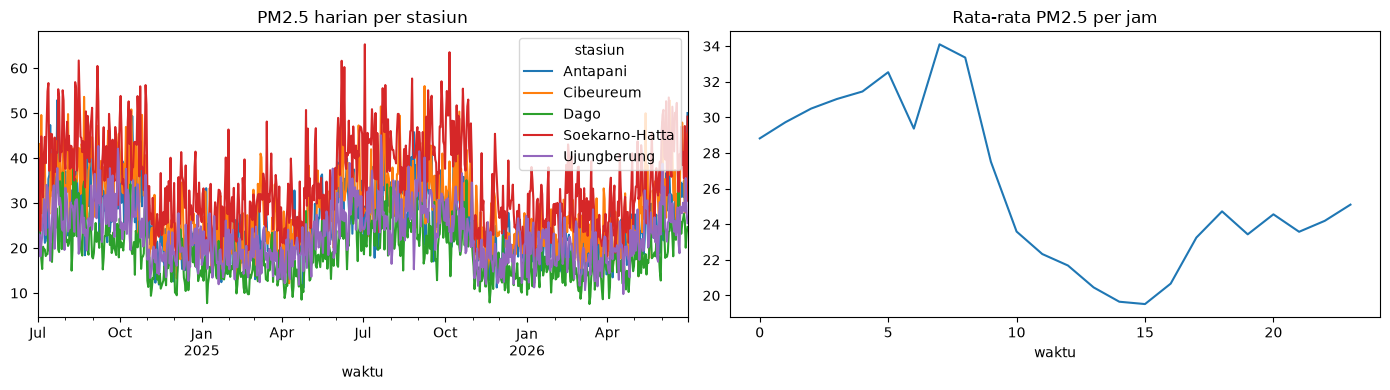

Proporsi jam > 55: 0.0275
                  count  mean   std  min   25%   50%   75%    max
stasiun                                                          
Antapani        17408.0  25.3  10.7  1.3  17.7  24.0  31.5   86.2
Cibeureum       17250.0  28.6  12.0  1.4  20.1  27.1  35.6   95.1
Dago            17411.0  18.9   7.9  1.0  13.3  18.0  23.5   59.8
Soekarno-Hatta  17376.0  34.6  14.7  1.5  24.0  32.8  43.2  128.4
Ujungberung     17398.0  22.9   9.3  1.2  16.5  22.1  28.4   78.0


In [22]:
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean.csv", parse_dates=["waktu"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.pivot(index="waktu", columns="stasiun", values="pm25_ugm3").resample("D").mean().plot(ax=ax[0], title="PM2.5 harian per stasiun")
df.groupby(df["waktu"].dt.hour)["pm25_ugm3"].mean().plot(ax=ax[1], title="Rata-rata PM2.5 per jam")
plt.tight_layout(); plt.show()

print("Proporsi jam > 55:", round((df["pm25_ugm3"] > 55).mean(), 4))
print(df.groupby("stasiun")["pm25_ugm3"].describe().round(1))

Jam 05-08 per stasiun:
 stasiun  Antapani  Cibeureum  Dago  Soekarno-Hatta  Ujungberung
jam                                                            
5            32.1       36.1  24.4            40.7         29.4
6            28.7       32.8  20.7            38.6         26.1
7            33.0       38.5  22.5            46.9         29.6
8            32.3       37.8  22.0            45.8         28.9

Kuantil:
                 0.500  0.990  0.999  1.000
stasiun                                   
Antapani         24.0   56.1   69.7   86.2
Cibeureum        27.1   62.8   78.0   95.1
Dago             18.0   41.8   52.0   59.8
Soekarno-Hatta   32.8   76.7   97.6  128.4
Ujungberung      22.1   48.9   62.2   78.0

Lonjakan >40 dalam 1 jam: 25


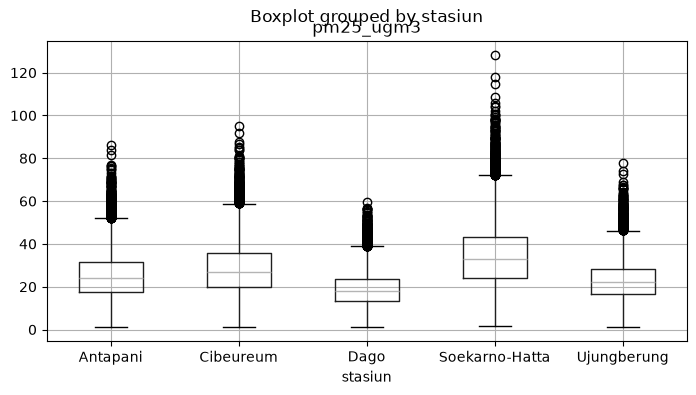

In [23]:
d = df.groupby("stasiun")["pm25_ugm3"]
jam = df.assign(jam=df["waktu"].dt.hour).pivot_table(index="jam", columns="stasiun", values="pm25_ugm3")

print("Jam 05-08 per stasiun:\n", jam.loc[5:8].round(1))
print("\nKuantil:\n", d.quantile([.5, .99, .999, 1]).unstack().round(1))
print("\nLonjakan >40 dalam 1 jam:", int((d.diff().abs() > 40).sum()))

df.boxplot("pm25_ugm3", by="stasiun", figsize=(8, 4)); plt.show()

In [24]:
t = df[["stasiun", "waktu", "pm25_ugm3"]].copy()
g = t.groupby("stasiun")["pm25_ugm3"]
t["selisih"], t["berikut"] = g.diff(), g.shift(-1)

L = t[t["selisih"].abs() > 40].copy()
L["sesaat"] = (L["berikut"] - (L["pm25_ugm3"] - L["selisih"])).abs() < 0.5 * L["selisih"].abs()

print(L["sesaat"].value_counts(), "\n")
print(L.groupby("stasiun").size(), "\n")
L.head(10)

sesaat
False    25
Name: count, dtype: int64 

stasiun
Antapani           3
Cibeureum          5
Soekarno-Hatta    16
Ujungberung        1
dtype: int64 



,stasiun,waktu,pm25_ugm3,selisih,berikut,sesaat
738,Antapani,2024-07-31 18:00:00,11.2,-41.0,11.0,False
9606,Antapani,2025-08-05 06:00:00,14.1,-44.0,25.1,False
10508,Antapani,2025-09-11 20:00:00,12.1,-51.4,16.4,False
19593,Cibeureum,2024-09-25 09:00:00,10.7,-54.6,15.6,False
20143,Cibeureum,2024-10-18 07:00:00,9.3,-44.1,11.6,False
28028,Cibeureum,2025-09-11 20:00:00,13.3,-56.2,16.4,False
28833,Cibeureum,2025-10-15 09:00:00,7.7,-48.7,10.1,False
28880,Cibeureum,2025-10-17 08:00:00,54.8,-40.3,50.5,False
53213,Soekarno-Hatta,2024-07-28 05:00:00,31.2,-45.9,36.3,False
53242,Soekarno-Hatta,2024-07-29 10:00:00,43.8,-43.4,38.9,False


In [25]:
idx = d.diff().abs().nlargest(5).index
for i in idx: print(df.loc[i-2:i+2, ["stasiun", "waktu", "pm25_ugm3"]], "\n")

              stasiun               waktu  pm25_ugm3
55181  Soekarno-Hatta 2024-10-18 05:00:00       80.3
55182  Soekarno-Hatta 2024-10-18 06:00:00       72.5
55183  Soekarno-Hatta 2024-10-18 07:00:00       14.8
55184  Soekarno-Hatta 2024-10-18 08:00:00       18.0
55185  Soekarno-Hatta 2024-10-18 09:00:00       20.9 

         stasiun               waktu  pm25_ugm3
28026  Cibeureum 2025-09-11 18:00:00       53.5
28027  Cibeureum 2025-09-11 19:00:00       69.5
28028  Cibeureum 2025-09-11 20:00:00       13.3
28029  Cibeureum 2025-09-11 21:00:00       16.4
28030  Cibeureum 2025-09-11 22:00:00       20.9 

              stasiun               waktu  pm25_ugm3
54631  Soekarno-Hatta 2024-09-25 07:00:00       53.8
54632  Soekarno-Hatta 2024-09-25 08:00:00       64.0
54633  Soekarno-Hatta 2024-09-25 09:00:00        8.7
54634  Soekarno-Hatta 2024-09-25 10:00:00       12.8
54635  Soekarno-Hatta 2024-09-25 11:00:00       14.7 

         stasiun               waktu  pm25_ugm3
19591  Cibeureum 2024-

In [26]:
df["target"] = df.groupby("stasiun")["pm25_ugm3"].shift(-3)
ok = df.dropna(subset=["pm25_ugm3", "target"])

train = ok[ok["waktu"] < "2026-03-01"]
val   = ok[(ok["waktu"] >= "2026-03-01") & (ok["waktu"] < "2026-05-01")]
test  = ok[ok["waktu"] >= "2026-05-01"]   # jangan dievaluasi dulu
print(len(train), len(val), len(test))

71777 7238 7205


In [27]:
from sklearn.metrics import mean_absolute_error

print("MAE baseline (val):", round(mean_absolute_error(val["target"], val["pm25_ugm3"]), 3))
y, a = val["target"] > 55, val["pm25_ugm3"] > 55
print("jam >55 di val:", y.sum())
print("recall   :", round((y & a).sum() / y.sum(), 3))
print("precision:", round((y & a).sum() / max(a.sum(), 1), 3))

MAE baseline (val): 6.255
jam >55 di val: 43
recall   : 0.186
precision: 0.186


## Baseline persistence

Prediksi PM2.5 tiga jam lagi = PM2.5 sekarang.

- Split: train 71.777 / val 7.238 / test 7.205 (berdasarkan waktu)
- MAE validation: 6,255 µg/m³
- Peringatan >55 µg/m³: 43 jam di validation, recall 0,186, precision 0,186
- Validation jatuh di musim hujan (jam >55 jarang), test di awal kemarau → test kemungkinan lebih sulit

In [28]:
print((df["pm25_ugm3"] == 0).sum(), df["pm25_ugm3"].isna().sum())

0 757


87 baris PM2.5 = 0,0 (tersebar di semua stasiun dan jam, tetangga normal) → NaN
  Total NaN PM2.5 sekarang 757 dari 87.600 (0,9%)